# About Dataset
**Context**

Dataset contains an airline passenger satisfaction survey. 

## Business Problem:

* Can we categorize the dimensions of passenger's satisfaction into smaller number of Factors?
* What factors are highly correlated to a satisfied (or dissatisfied) passenger?
* Can you predict passenger satisfaction?

In order to do that, we'll perform Factor Analysis first then make a prediction model

https://www.kaggle.com/code/bahaulug/factor-analysis-and-pca

https://www.datacamp.com/tutorial/introduction-factor-analysis

## Factor Analysis (FA)

Factor Analysis (FA) is an exploratory data analysis method used to search influential underlying factors or latent variables from a set of observed variables. It helps in data interpretations by reducing the number of variables. 

Factor analysis is a linear statistical model. It is used to explain the variance among the observed variable and condense a set of the observed variable into the unobserved variable called factors. Observed variables are modeled as a linear combination of factors and error terms (Source). Factor or latent variable is associated with multiple observed variables. ([Ref.](https://www.cs.princeton.edu/~bee/courses/scribe/lec_10_02_2013.pdf))


### Types of Factor Analysis

There are two distinct approaches in Factor Analysis:

 * **Exploratory Factor Analysis (EFA):** EFA is used when the exact nature of the structure within a set of variables is unknown. It allows for the identification of the number of factors and the relationships among variables, providing a flexible method for exploring data without predefined hypotheses about the factor structure.
 * **Confirmatory Factor Analysis (CFA):** y, CFA is applied when there is a specific hypothesized model regarding the factor structure. It tests the fit of the observed data to the hypothesized model, allowing for a rigorous assessment of how well the data aligns with the proposed factor structure. CFA is particularly useful for validating theories and models in research, offering a structured approach to factor analysis.

## Factor Analysis Process

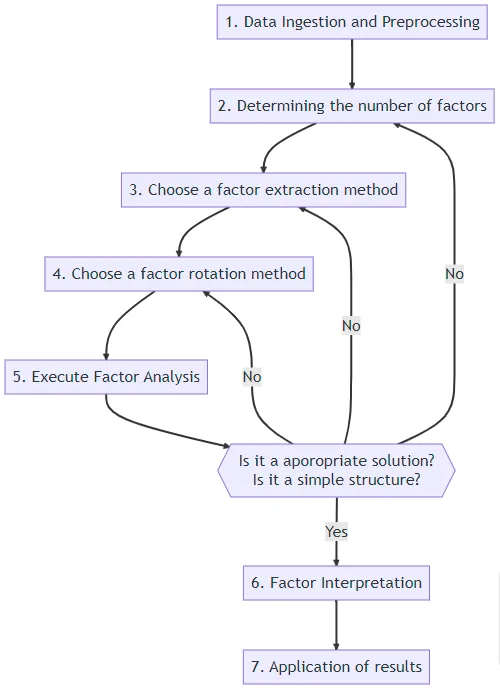

**Assumptions for FA:**

* There are no outliers in data.
* Sample size should be greater than the factor.
* There should not be perfect multicollinearity.
* There should not be homoscedasticity between the variables.

## Terminology

**What is a factor?**

A factor is a latent variable which describes the association among the number of observed variables. The maximum number of factors are equal to a number of observed variables. Every factor explains a certain variance in observed variables. The factors with the lowest amount of variance were dropped. Factors are also known as latent variables or hidden variables or unobserved variables or Hypothetical variables.

**What are the factor loadings?**

The factor loading is a matrix which shows the relationship of each variable to the underlying factor. It shows the correlation coefficient for observed variable and factor. It shows the variance explained by the observed variables.

**What is Eigenvalues?**

Eigenvalues represent variance explained each factor from the total variance. It is also known as characteristic roots.

**What are Communalities?**

Commonalities are the sum of the squared loadings for each variable. It represents the common variance. It ranges from 0-1 and value close to 1 represents more variance.

**What is Factor Rotation?**

Rotation is a tool for better interpretation of factor analysis. Rotation can be orthogonal or oblique. It re-distributed the commonalities with a clear pattern of loadings.

**Adequacy Test** </br>
Before you perform factor analysis, need to evaluate the “factorability” ofther dataset. Factorability means "can we found the factors in the dataset?".
 There are two methods to check the factorability or sampling adequacy:

Bartlett’s Test
Kaiser-Meyer-Olkin Test
Bartlett’s test of sphericity checks whether or not the observed variables intercorrelate at all using the observed correlation matrix against the identity matrix. If the test found statistically insignificwe, you should not employ a factor analysis.

## Determining the number of factors
Determining the optimal number of factors in factor analysis is a crucial step in the process. Several methods can be used to make this decision. Here are some of the most common techniques:
**Summary of Methods**
* **Scree Plot:**	Identify the "elbow point" where eigenvalues level off.
* **Kaiser Criterion:**	Retain factors with eigenvalues > 1.
* **Parallel Analysis:**	Compare eigenvalues to those from random datasets.
* **Velicer's MAP(Minimum Average Partial (correlation)) Test:** The optimal number of factors is the point where removing an additional factor significantly worsens the fit.
* **Cumulative Variance:**	Retain enough factors to explain 70-80% of the total variance.
ysis.

## Factor Extraction Methods (Estimation of Commonality)
**Common Factor Extraction Methods** 

* Principal Component Analysis (PCA): Captures total variance (common + unique variance).
* Principal Axis Factoring (PAF): Captures only shared variance (common variance).
* Maximum Likelihood Estimation (MLE): Provides statistical testing for model fit.
* Iterated Principal Factor (IPF): Iterative method for refining communalities.

If the sample size is large, the maximum likelihood method should be used; Principal Component Analysis has problems and should be eliminated from the selection.

## Factor Rotation Methods
After extracting factors in Factor Analysis, the next step is often to rotate the factors to make them more interpretable. Factor rotation aims to simplify the factor structure so that each factor has high loadings for some variables and low loadings for others. This makes it easier to identify the underlying constructs.

**Types of Factor Rotation Methods** </br>
Factor rotation methods are broadly categorized into two types: </br>

* Orthogonal Rotation (Factors remain uncorrelated)
* Oblique Rotation (Factors are allowed to be correlated)

**Summary of Factor Rotation Methods**

* Varimax (Type-Orthogonal):	Maximizes variance of squared loadings within each factor; most widely used.
* Quartimax (Type- Orthogonal):	Simplifies the structure by focusing on minimizing the number of factors explaining each variable.
* Equamax	(Type- Orthogonal)	A hybrid of Varimax and Quartimax.
* Promax (Type- Oblique):	Fast oblique rotation, allows factors to correlate.
* Oblimin (Type- Oblique):	Flexible oblique rotation method; allows factors to correlate.

# Data Ingestion and Proprocessing

### Library Instalation 

In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)
import seaborn as sns
import matplotlib.pyplot as plt
import seaborn as sns

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

/kaggle/input/train.csv
/kaggle/input/test.csv


In [2]:
import warnings
warnings.filterwarnings("ignore", "is_categorical_dtype")
warnings.filterwarnings("ignore", "use_inf_as_na")
warnings.simplefilter(action='ignore', category=FutureWarning)

## Read data

In [3]:

# Create combined data from test and train dataset
dftrain = pd.read_csv('/kaggle/input/train.csv',index_col=0)
dftest = pd.read_csv('/kaggle/input/test.csv',index_col=0)
df_ori = pd.concat([dftrain, dftest], sort=False) # concatenate the train and test for generalizability


In [4]:
df_ori.info()

<class 'pandas.core.frame.DataFrame'>
Index: 129880 entries, 0 to 25975
Data columns (total 24 columns):
 #   Column                             Non-Null Count   Dtype  
---  ------                             --------------   -----  
 0   id                                 129880 non-null  int64  
 1   Gender                             129880 non-null  object 
 2   Customer Type                      129880 non-null  object 
 3   Age                                129880 non-null  int64  
 4   Type of Travel                     129880 non-null  object 
 5   Class                              129880 non-null  object 
 6   Flight Distance                    129880 non-null  int64  
 7   Inflight wifi service              129880 non-null  int64  
 8   Departure/Arrival time convenient  129880 non-null  int64  
 9   Ease of Online booking             129880 non-null  int64  
 10  Gate location                      129880 non-null  int64  
 11  Food and drink                     129880 non

In [5]:
# Copy Numerical columns 
df = df_ori.copy()
df = df.iloc[:,6:23]
df = df.dropna() # checking missing data
df

,Flight Distance,Inflight wifi service,Departure/Arrival time convenient,Ease of Online booking,Gate location,Food and drink,Online boarding,Seat comfort,Inflight entertainment,On-board service,Leg room service,Baggage handling,Checkin service,Inflight service,Cleanliness,Departure Delay in Minutes,Arrival Delay in Minutes
0,460,3,4,3,1,5,3,5,5,4,3,4,4,5,5,25,18.0
1,235,3,2,3,3,1,3,1,1,1,5,3,1,4,1,1,6.0
2,1142,2,2,2,2,5,5,5,5,4,3,4,4,4,5,0,0.0
3,562,2,5,5,5,2,2,2,2,2,5,3,1,4,2,11,9.0
4,214,3,3,3,3,4,5,5,3,3,4,4,3,3,3,0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
25971,526,3,3,3,1,4,3,4,4,3,2,4,4,5,4,0,0.0
25972,646,4,4,4,4,4,4,4,4,4,5,5,5,5,4,0,0.0
25973,828,2,5,1,5,2,1,2,2,4,3,4,5,4,2,0,0.0
25974,1127,3,3,3,3,4,4,4,4,3,2,5,4,5,4,0,0.0


The above dataframe shows all the parameters that contribute to passengers' satisfaction.

In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 129487 entries, 0 to 25975
Data columns (total 17 columns):
 #   Column                             Non-Null Count   Dtype  
---  ------                             --------------   -----  
 0   Flight Distance                    129487 non-null  int64  
 1   Inflight wifi service              129487 non-null  int64  
 2   Departure/Arrival time convenient  129487 non-null  int64  
 3   Ease of Online booking             129487 non-null  int64  
 4   Gate location                      129487 non-null  int64  
 5   Food and drink                     129487 non-null  int64  
 6   Online boarding                    129487 non-null  int64  
 7   Seat comfort                       129487 non-null  int64  
 8   Inflight entertainment             129487 non-null  int64  
 9   On-board service                   129487 non-null  int64  
 10  Leg room service                   129487 non-null  int64  
 11  Baggage handling                   129487 non

# EDA & Preprocessing

In [7]:
# Check any null value
df.isnull().sum()

Flight Distance                      0
Inflight wifi service                0
Departure/Arrival time convenient    0
Ease of Online booking               0
Gate location                        0
Food and drink                       0
Online boarding                      0
Seat comfort                         0
Inflight entertainment               0
On-board service                     0
Leg room service                     0
Baggage handling                     0
Checkin service                      0
Inflight service                     0
Cleanliness                          0
Departure Delay in Minutes           0
Arrival Delay in Minutes             0
dtype: int64

## No Homoscedasticity Between Variables
Homoscedasticity refers to constant variance across variables. In factor analysis, we generally want heteroscedasticity, as factor analysis assumes different variances for different variables.

You can visualize homoscedasticity with scatter plots:
If the scatter plot shows a funnel shape or patterns, there may be heteroscedasticity.

**Show in pairplot already**

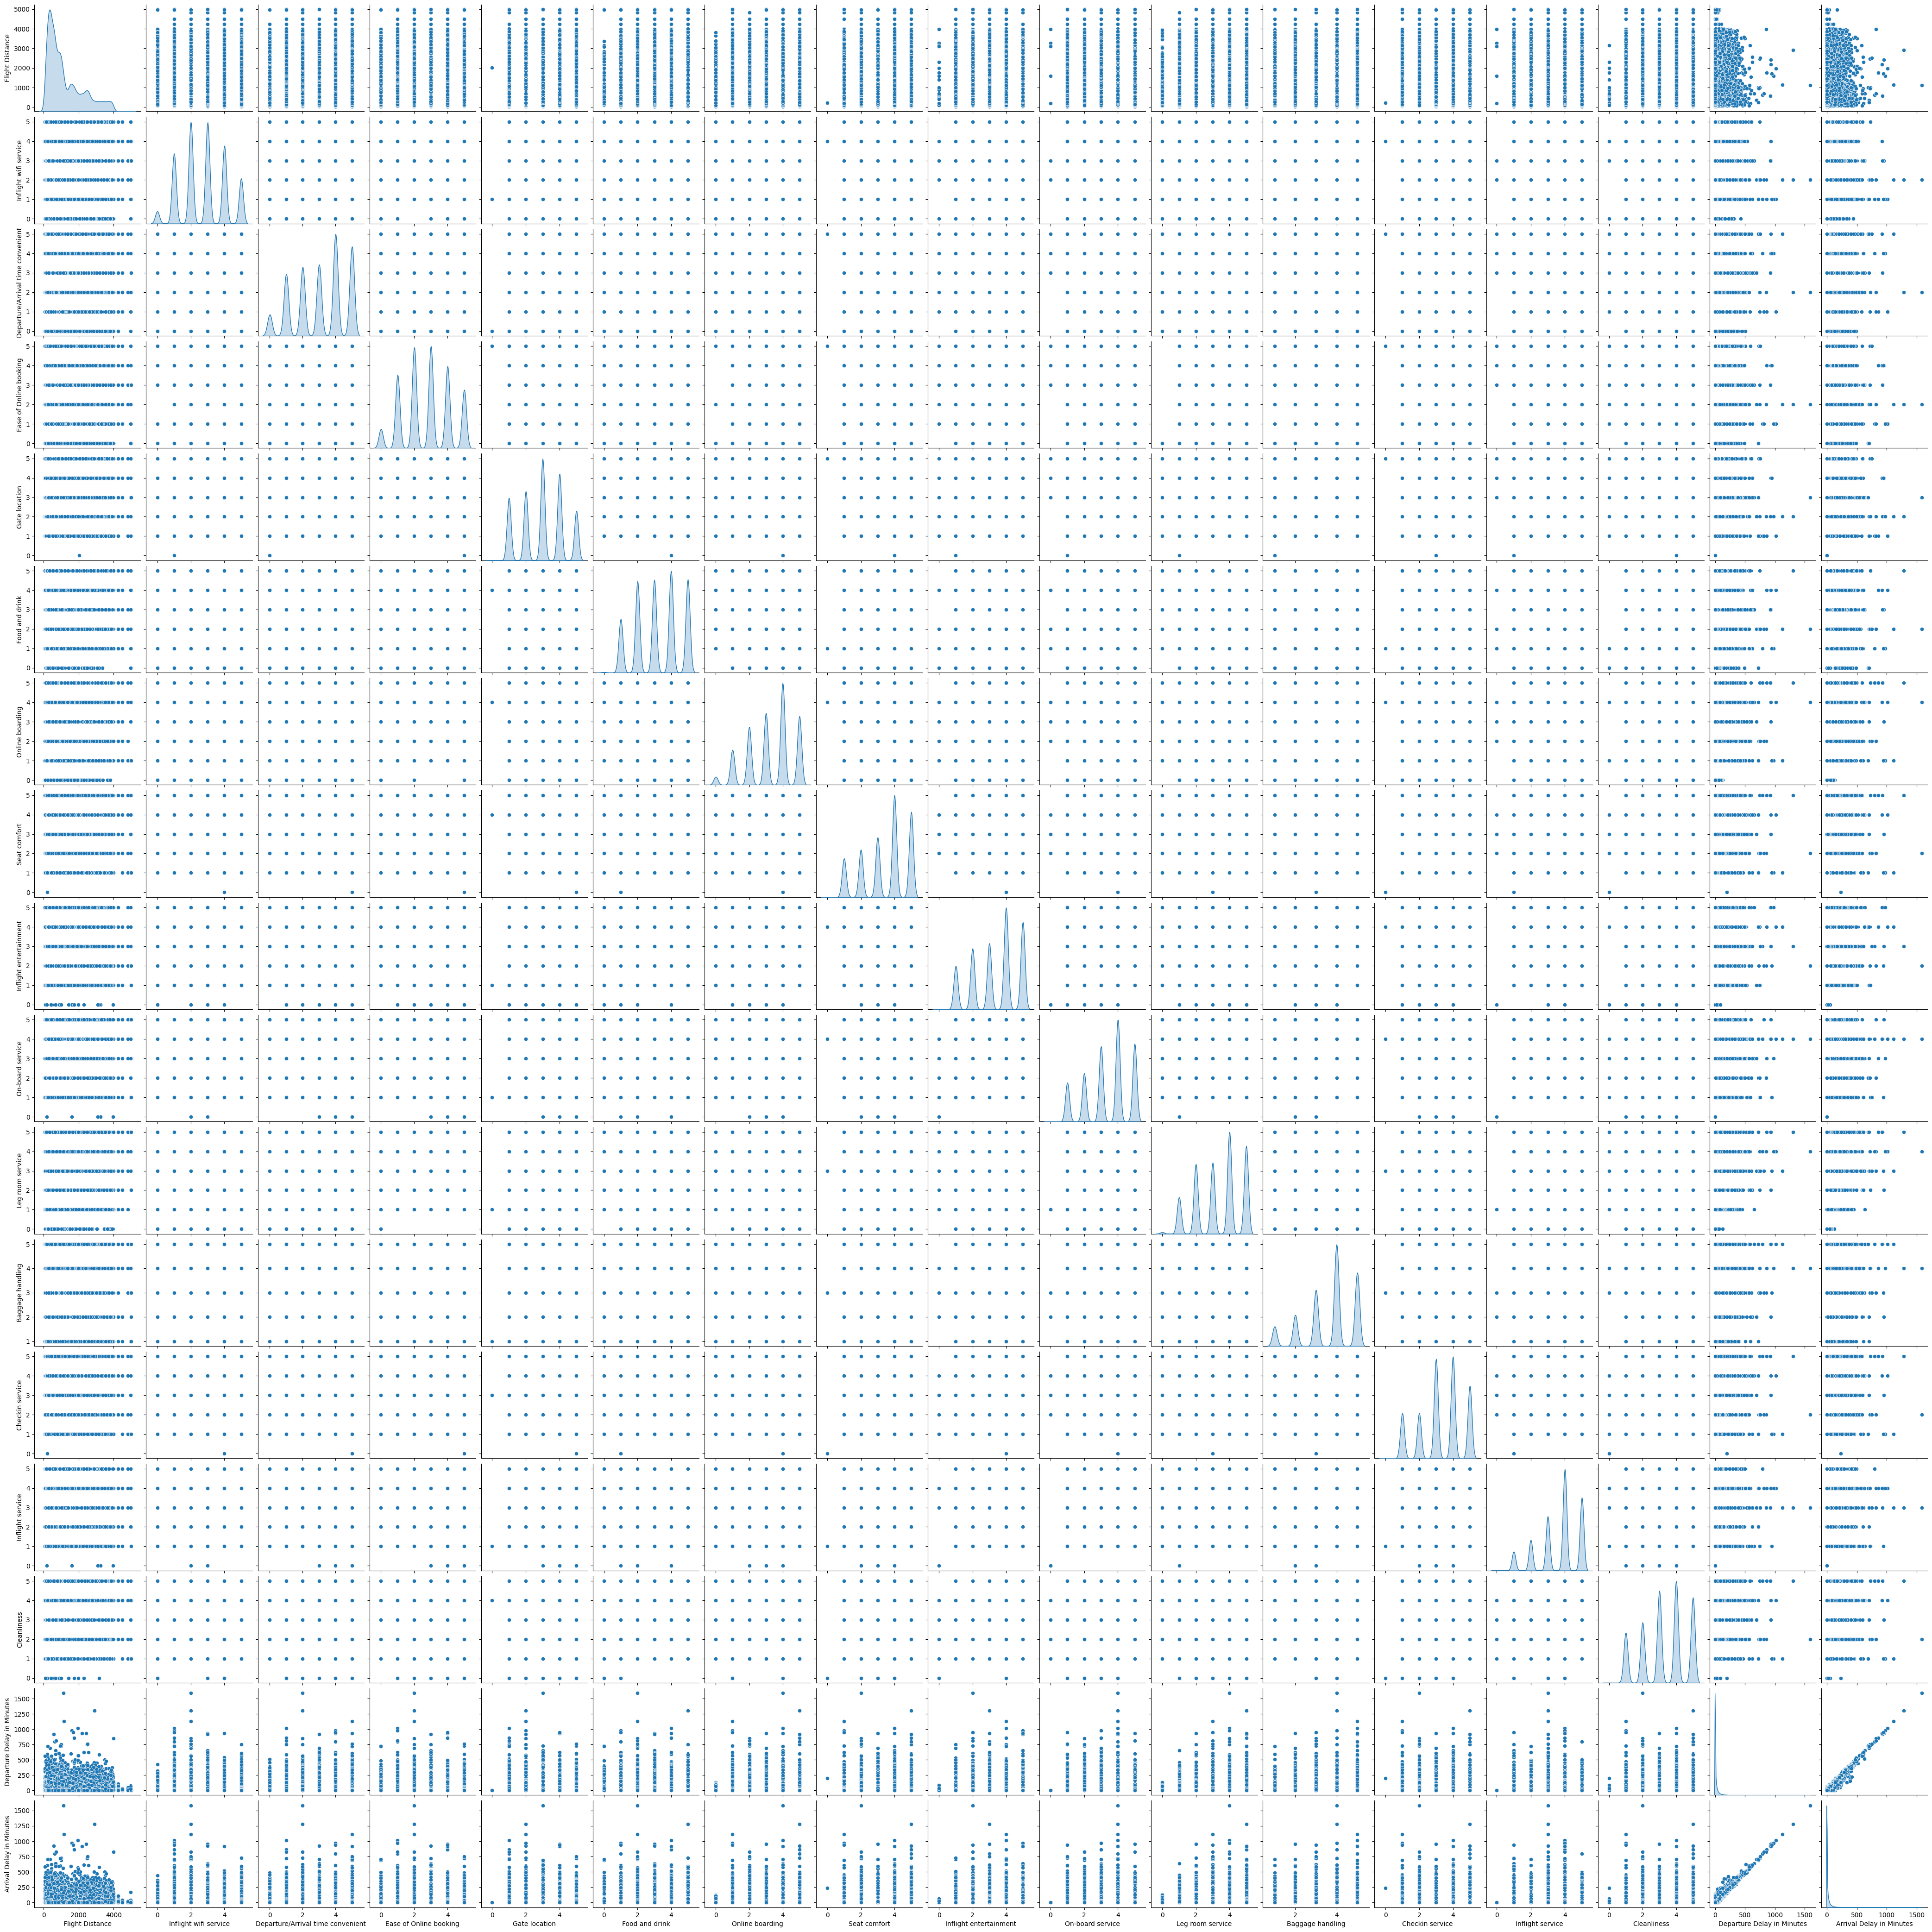

In [8]:
# pairplot
sns.pairplot(df, diag_kind='kde')
plt.show()

In [9]:
# Labeling numeric and catagorical columns 
def grab_column_names(df, cardinality_threshold=20):
    numeric_columns = df.select_dtypes(include=["number"]).columns.tolist()
    
    categorical_columns = df.select_dtypes(include=["object", "category"]).columns.tolist() 
    
    cardinal_columns = [col for col in categorical_columns if df[col].nunique() > cardinality_threshold]
    
    return numeric_columns, categorical_columns, cardinal_columns 



In [10]:
# Select numerical columns
numeric_columns, categorical_columns, cardinal_columns = grab_column_names(df)     
print("Numeric columns :", numeric_columns,)
print("Catagorical Columns:", categorical_columns )

Numeric columns : ['Flight Distance', 'Inflight wifi service', 'Departure/Arrival time convenient', 'Ease of Online booking', 'Gate location', 'Food and drink', 'Online boarding', 'Seat comfort', 'Inflight entertainment', 'On-board service', 'Leg room service', 'Baggage handling', 'Checkin service', 'Inflight service', 'Cleanliness', 'Departure Delay in Minutes', 'Arrival Delay in Minutes']
Catagorical Columns: []


In [11]:
# Ploting all Numerical columns in histogram

def plot_histograms(df, columns, rows=2, cols=3):
    """
    Plot histograms for specified columns in a dataframe.

    Args:
    df (pandas.DataFrame): The dataframe containing the data.
    columns (list): List of column names to plot.
    rows (int): Number of rows in the plot grid. Default is 2.
    cols (int): Number of columns in the plot grid. Default is 3.
    """ 
    fig, axes = plt.subplots(rows, cols, figsize=(5*cols, 4*rows))
    axes = axes.flatten()  # Flatten axes array for easy indexing

    for i, col in enumerate(columns):
        if i < len(axes):  # Check if we have enough subplots
            sns.histplot(df[col], kde=True, ax=axes[i], bins=10)
            axes[i].set_title(col)
            axes[i].set_xlabel('')  # Remove x-label as it's redundant with title

    # Remove unused subplots
    for j in range(i+1, len(axes)):
        fig.delaxes(axes[j])

    plt.tight_layout()
    plt.show() 
    


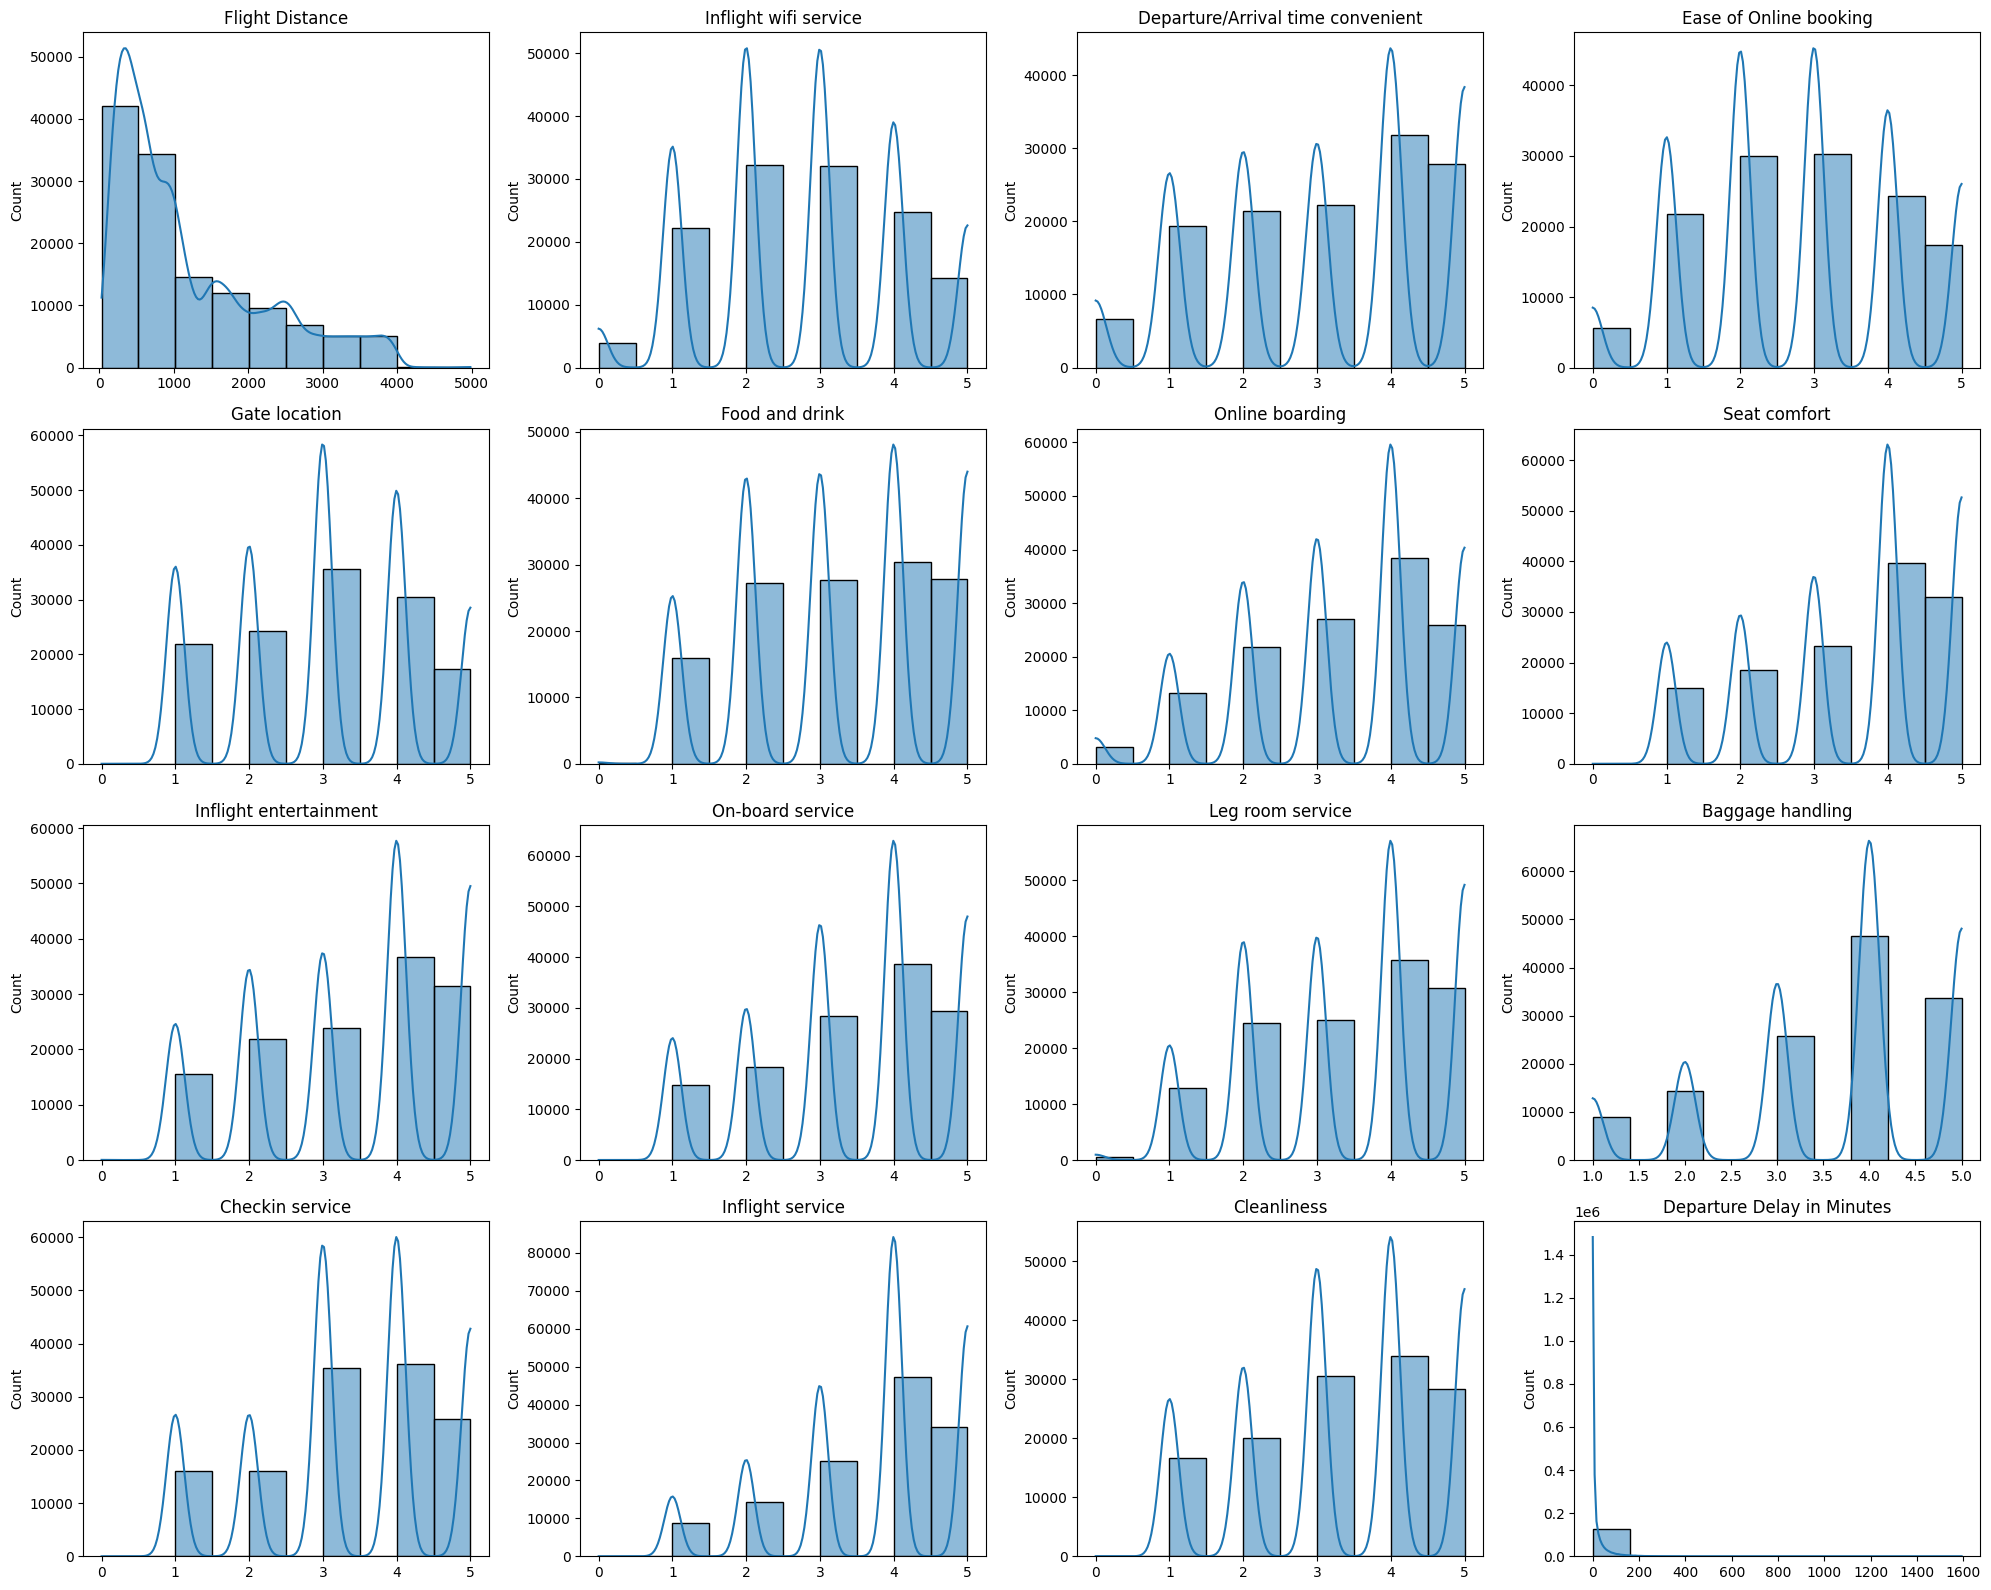

In [12]:
plot_histograms(df, numeric_columns, rows=4, cols=4)    


## No Outliers in Data

In [13]:
# Ploting all Numerical columns in histogram

def plot_box(df, columns, rows=2, cols=3):
    """
    Plot histograms for specified columns in a dataframe.

    Args:
    df (pandas.DataFrame): The dataframe containing the data.
    columns (list): List of column names to plot.
    rows (int): Number of rows in the plot grid. Default is 2.
    cols (int): Number of columns in the plot grid. Default is 3.
    """ 
    fig, axes = plt.subplots(rows, cols, figsize=(5*cols, 4*rows))
    axes = axes.flatten()  # Flatten axes array for easy indexing

    for i, col in enumerate(columns):
        if i < len(axes):  # Check if we have enough subplots
            sns.boxplot(x=df[col], ax=axes[i])
            axes[i].set_title(col)
            axes[i].set_xlabel('')  # Remove x-label as it's redundant with title

    # Remove unused subplots
    for j in range(i+1, len(axes)):
        fig.delaxes(axes[j])

    plt.tight_layout()
    plt.show() 

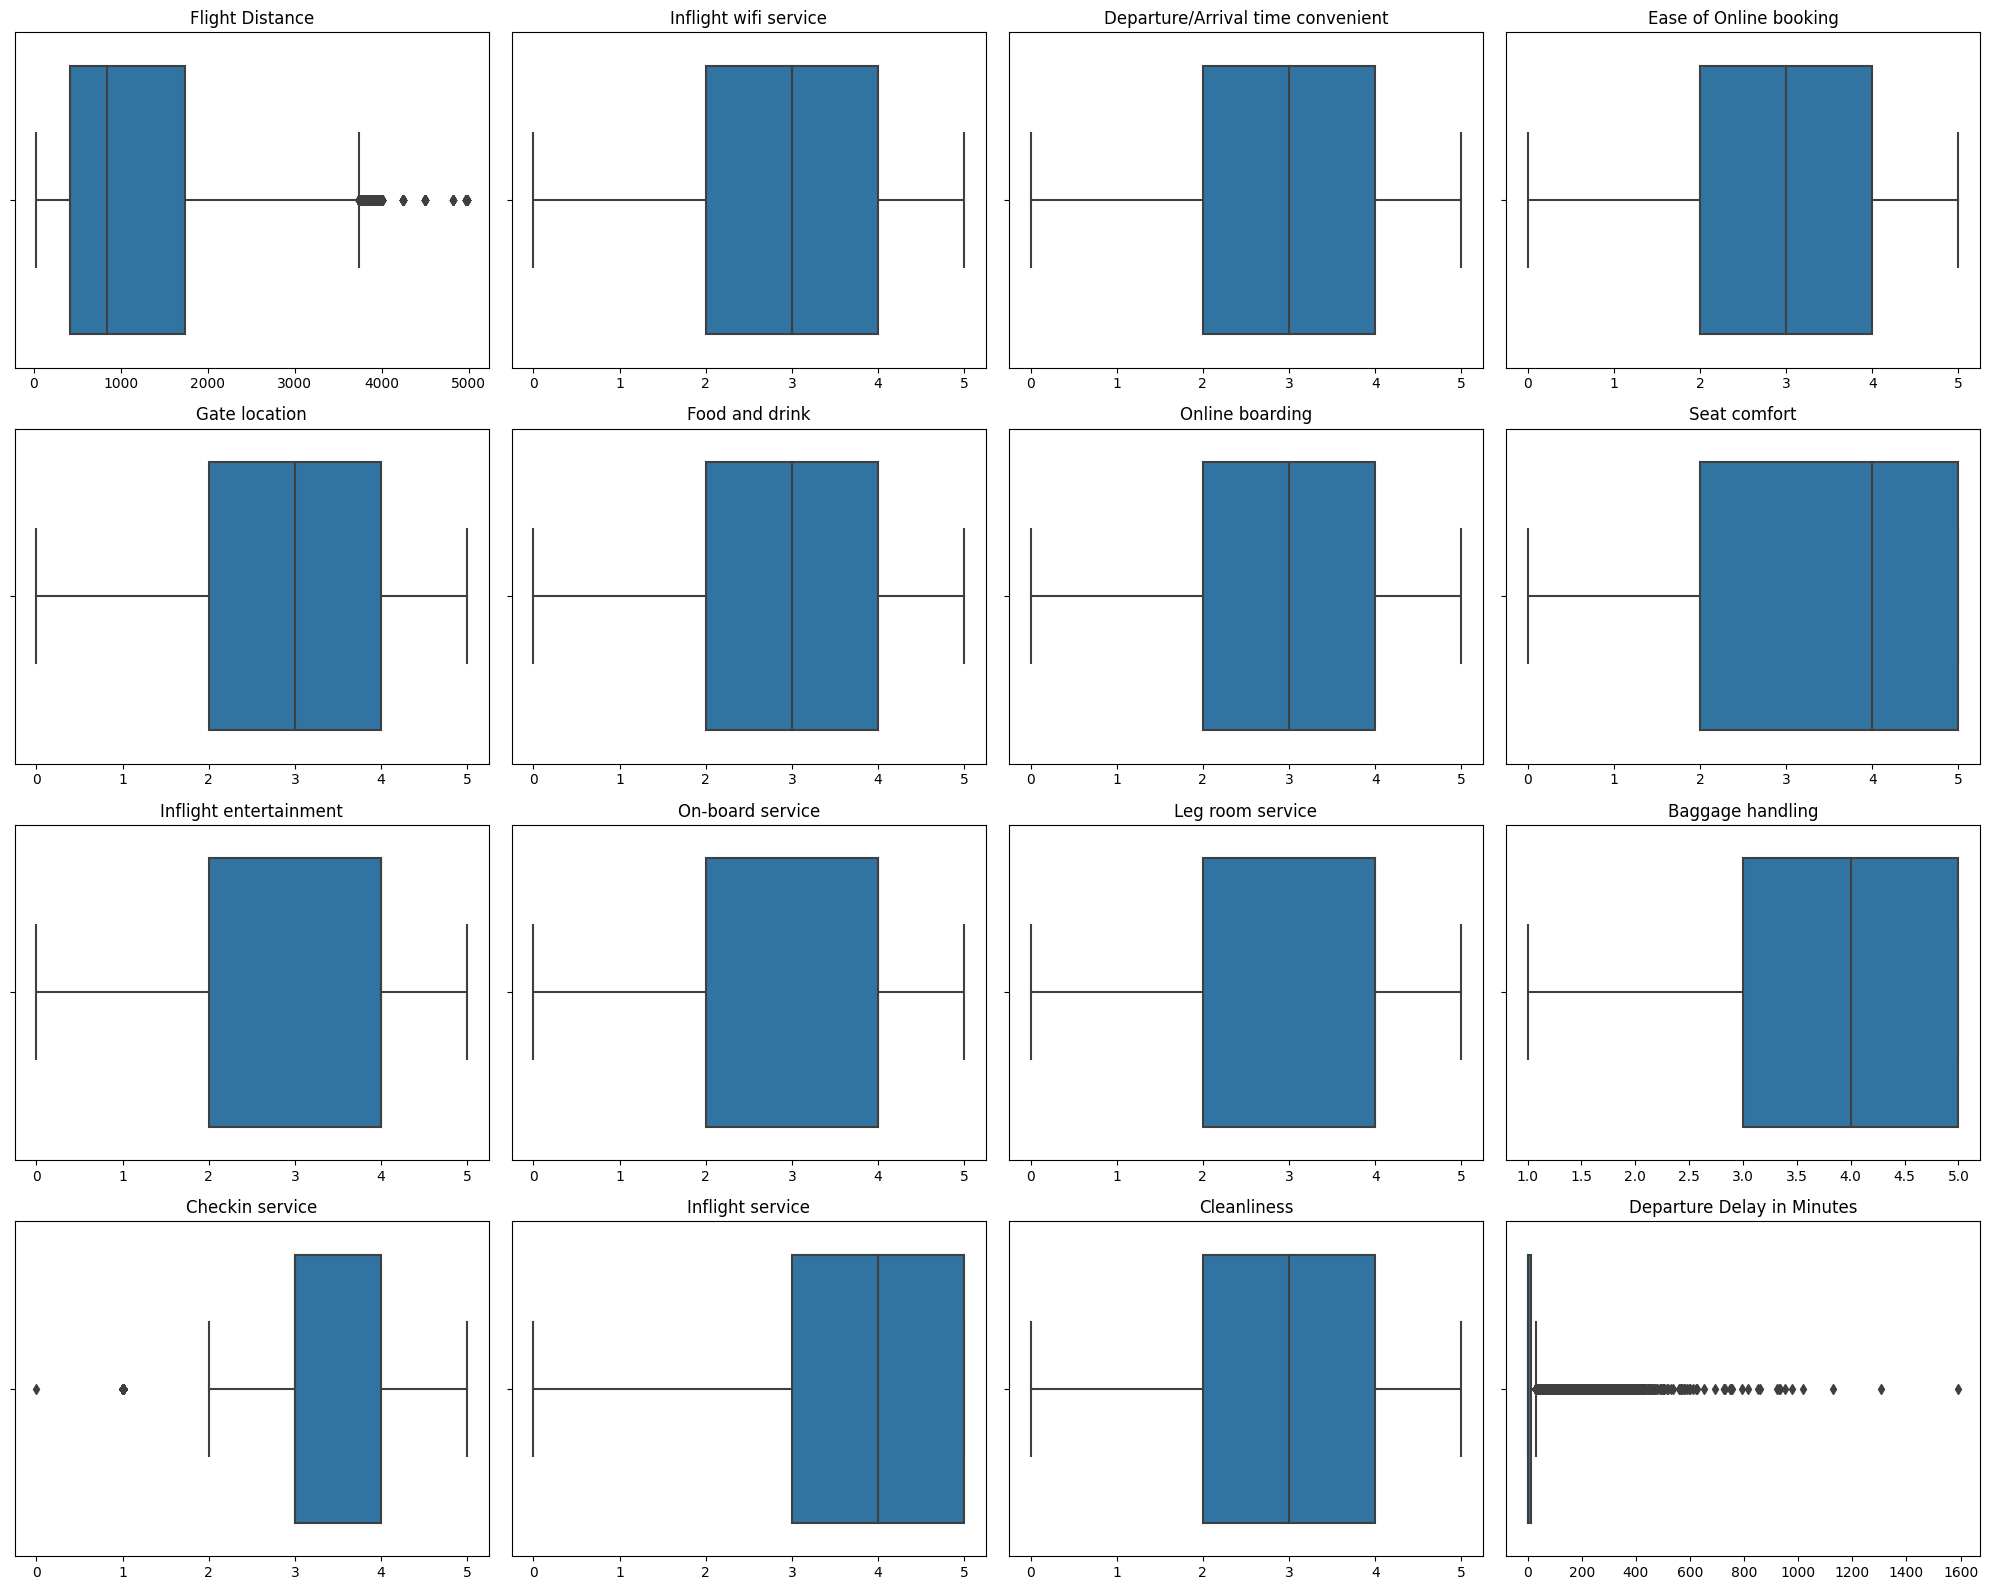

In [14]:
plot_box(df, numeric_columns, rows=4, cols=4)

## Standardize the data
It is necessary to standardize the data before performing Factor Analysis (FA)

In [15]:
from sklearn.preprocessing import StandardScaler

# Standardize the data
scaler = StandardScaler()
df_standardized = scaler.fit_transform(df)
# Convert back to DataFrame if needed
df = pd.DataFrame(df_standardized, columns=df.columns)

## No Perfect Multicollinearity
Multicollinearity occurs when variables are highly correlated. You can check this using the correlation matrix, Condition index and Variance Inflation Factor (VIF)

**Correlation matrix** </br>
One widely used technique to detect multicollinearity is through a correlation matrix that helps visualize the strength of relationships between variables. The matrix shows the pairwise correlation coefficients between the variables, which indicates how strongly they are linearly related (values range from -1 to 1). A rule of thumb I use is that the absolute correlation values above 0.6 indicates strong multicollinearity.

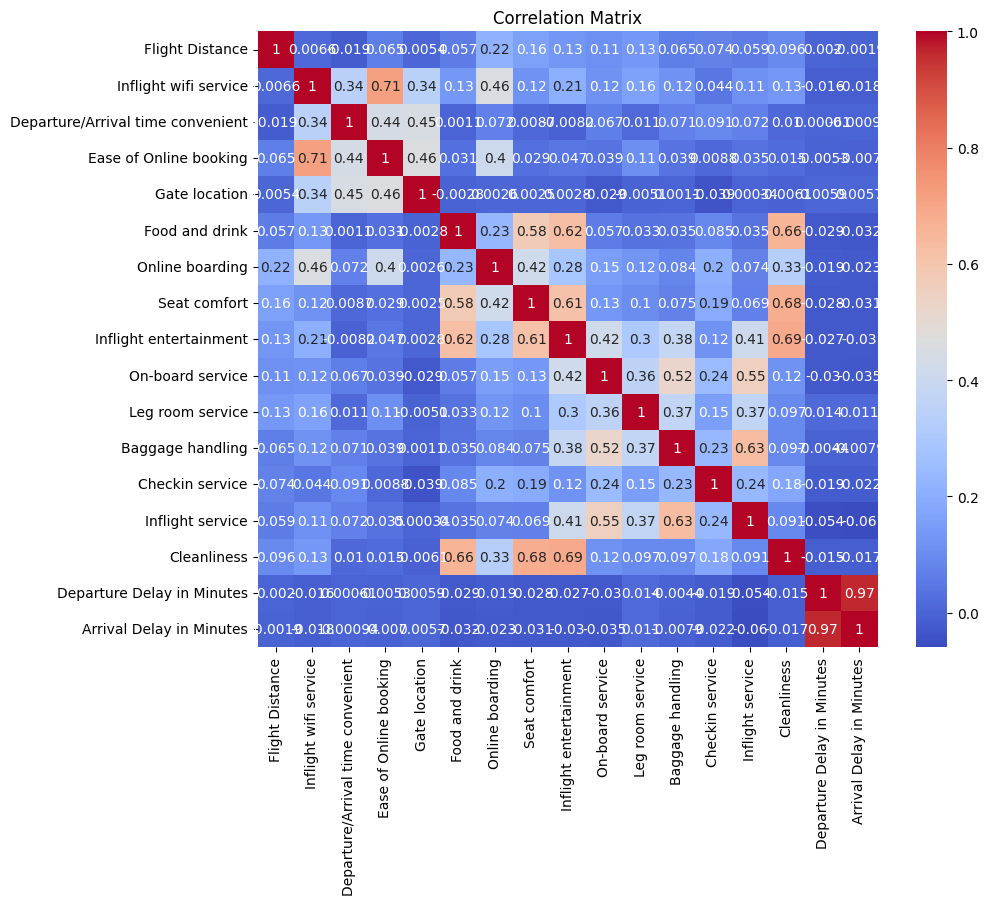

In [16]:
# Plot correlation matrix
plt.figure(figsize=(10, 8))
sns.heatmap(df.corr(), annot=True, cmap="coolwarm")
plt.title("Correlation Matrix")
plt.show()

In [17]:
# Identify highly correlated variables (threshold = 0.8)
high_corr = df.corr().abs().stack().reset_index()
high_corr = high_corr[high_corr[0] > 0.8]
high_corr = high_corr[high_corr['level_0'] != high_corr['level_1']]
print("Highly Correlated Variables:")
print(high_corr)

Highly Correlated Variables:
                        level_0                     level_1         0
271  Departure Delay in Minutes    Arrival Delay in Minutes  0.965291
287    Arrival Delay in Minutes  Departure Delay in Minutes  0.965291


**Variance inflation factor (VIF)** </br>
Variance inflation factor (VIF) is one of the most common techniques for detecting multicollinearity. In simple terms, it gives a numerical value that indicates how much the variance of a regression coefficient is inflated due to multicollinearity. A VIF value greater than 5 indicates moderate multicollinearity, while values above 10 suggest severe multicollinearity.

In [18]:
from statsmodels.stats.outliers_influence import variance_inflation_factor

# Calculate VIF for each variable
vif_data = pd.DataFrame()
vif_data["Variable"] = df.columns
vif_data["VIF"] = [round(variance_inflation_factor(df.values, i), 4) for i in range(len(df.columns))]

# Sort the VIF values in descending order
print(vif_data.sort_values(by="VIF", ascending=False))

                             Variable      VIF
16           Arrival Delay in Minutes  14.6802
15         Departure Delay in Minutes  14.6678
8              Inflight entertainment   3.7851
14                        Cleanliness   2.8324
3              Ease of Online booking   2.6396
1               Inflight wifi service   2.3786
7                        Seat comfort   2.3617
5                      Food and drink   2.1613
13                   Inflight service   2.0498
11                   Baggage handling   1.8878
6                     Online boarding   1.8193
9                    On-board service   1.7543
4                       Gate location   1.4871
2   Departure/Arrival time convenient   1.4317
10                   Leg room service   1.3012
12                    Checkin service   1.2149
0                     Flight Distance   1.0942


> **A VIF value greater than 5 indicates moderate multicollinearity, while values above 10 suggest severe multicollinearity**.

**Condition index** </br>
Condition index is another diagnostic tool for detecting multicollinearity, with values above 10 indicating moderate multicollinearity and values above 30 indicating severe multicollinearity. The condition index works by checking how much the independent variables are related to each other by examining the relationships between their eigenvalues.

In [19]:
from numpy.linalg import eigvals

# Calculate the condition index
eigenvalues = eigvals(df.corr())
condition_index = max(eigenvalues) / min(eigenvalues)

print(f'Condition Index: {condition_index}')

Condition Index: 110.86402878134933


## Techniques to Address Multicollinearity

1. Remove Highly Correlated Variables
2. Combine Correlated Variables
3. Principal Component Analysis (PCA) for Dimensionality Reduction
4. Factor Rotation: </br>
        After extracting factors, apply rotation to simplify factor structure and make interpretation easier.</br>
        Varimax (Orthogonal Rotation): Preserves uncorrelated factors. </br>
        **Oblimin (Oblique Rotation):** Allows for correlated factors. </br>

# Factor analysis

### Importing Factor Analyzer
Let's install the package for factor analysis called Factor Analyzer.

In [20]:
# installing Factor Analyzer
! pip install factor_analyzer 


     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 42.8/42.8 kB 574.4 kB/s eta 0:00:00
  Installing build dependencies ... - \ | / - \ done
  Getting requirements to build wheel ... - done
  Preparing metadata (pyproject.toml) ... - done
  Created wheel for factor_analyzer: filename=factor_analyzer-0.5.1-py2.py3-none-any.whl size=42568 sha256=2111957d793d6a4639d941893e0e422909d9c5edb43ff7fe1f49368f4f4b4550
  Stored in directory: /root/.cache/pip/wheels/24/59/82/6493618e30ed1cb7a013b9e1b0c9e17de80b04dfcef4ba8a4d
Successfully built factor_analyzer


In [21]:
from factor_analyzer import FactorAnalyzer # Then, we import the installed package into our notebook.

## Adequacy Test
1. Bartlett's Test: to check whether observed variables intercorrelate at all using the observed correlation matrix
2. Kaiser-Meyer-Olkin Test: to measures the suitability of data for factor analysis 

[Source](https://www.datacamp.com/community/tutorials/introduction-factor-analysis)

**Bartlett’s test** of sphericity checks whether or not the observed variables intercorrelate at all using the observed correlation matrix against the identity matrix. If the test found statistically insignificant, you should not employ a factor analysis.

In [22]:
# Barlett's

from factor_analyzer.factor_analyzer import calculate_bartlett_sphericity
calculate_bartlett_sphericity(df)

(1112103.0881659335, 0.0)

Result interpretation: In this Bartlett ’s test, the p-value is 0. The test was statistically significant, indicating that the observed correlation matrix is not an identity matrix.
e.

**Kaiser-Meyer-Olkin (KMO)** Test measures the suitability of data for factor analysis. It determines the adequacy for each observed variable and for the complete model. KMO estimates the proportion of variance among all the observed variable. Lower proportion id more suitable for factor analysis. KMO values range between 0 and 1. **Value of KMO less than 0.6 is considered inadequate.**

In [23]:
# KMO

from factor_analyzer.factor_analyzer import calculate_kmo
kmo_all, kmo_model = calculate_kmo(df)
if kmo_model >.6:
    print(f'The overall KMO for our data is {kmo_model: .2f}, which is excellent. This value indicates that you can proceed with factor analysis.')

else:
    
    print(f'The overall KMO for our data is {kmo_model: .2f}, which is  inadequate for Factor analysis.')

The overall KMO for our data is  0.73, which is excellent. This value indicates that you can proceed with factor analysis.


**Both Bartlett's Test and KMO indicates that the dataframe is good to go for factor analysis.**

## Identify the Number of Factors

In [24]:
df.head()

,Flight Distance,Inflight wifi service,Departure/Arrival time convenient,Ease of Online booking,Gate location,Food and drink,Online boarding,Seat comfort,Inflight entertainment,On-board service,Leg room service,Baggage handling,Checkin service,Inflight service,Cleanliness,Departure Delay in Minutes,Arrival Delay in Minutes
0,-0.731999,0.204220,0.617410,0.173519,-1.546271,1.349963,-0.187111,1.181364,1.230701,0.479240,-0.266751,0.311941,0.547933,1.153847,1.304624,0.273026,0.075623
1,-0.957550,0.204220,-0.692535,0.173519,0.018061,-1.657783,-0.187111,-1.850863,-1.767475,-1.851712,1.252860,-0.535461,-1.821471,0.303947,-1.740400,-0.359673,-0.236345
2,-0.048329,-0.548095,-0.692535,-0.539923,-0.764105,1.349963,1.293662,1.181364,1.230701,0.479240,-0.266751,0.311941,0.547933,0.303947,1.304624,-0.386036,-0.392329
3,-0.629749,-0.548095,1.272383,1.600402,1.582393,-0.905846,-0.927497,-1.092806,-1.017931,-1.074728,1.252860,-0.535461,-1.821471,0.303947,-0.979144,-0.096049,-0.158353
4,-0.978601,0.204220,-0.037562,0.173519,0.018061,0.598027,1.293662,1.181364,-0.268387,-0.297744,0.493055,0.311941,-0.241868,-0.545953,-0.217888,-0.386036,-0.392329


In [25]:
# instantiate the Factor Analyzer
fa = FactorAnalyzer() 

# Fit the dataframe using Factor Analyzer
fa.fit(df)

# Identify the eigenvalues
ev, v = fa.get_eigenvalues() #eigenvalues

# display the eigenvalues
ev

array([3.84460867, 2.37270203, 2.1695714 , 1.96233743, 1.14645441,
       0.95090768, 0.91318908, 0.68951396, 0.53695417, 0.49418638,
       0.46124804, 0.36634408, 0.32497292, 0.2932581 , 0.25238489,
       0.18668817, 0.03467859])

### Kaiser's Criterion:
This rule suggests retaining factors with eigenvalues greater than 1.</br>
Here only for **5-factors eigenvalues are greater than one**. It means we need to choose only 5 factors (or unobserved variables). The above array of eigen values show that we can create five factors.

### The scree plot

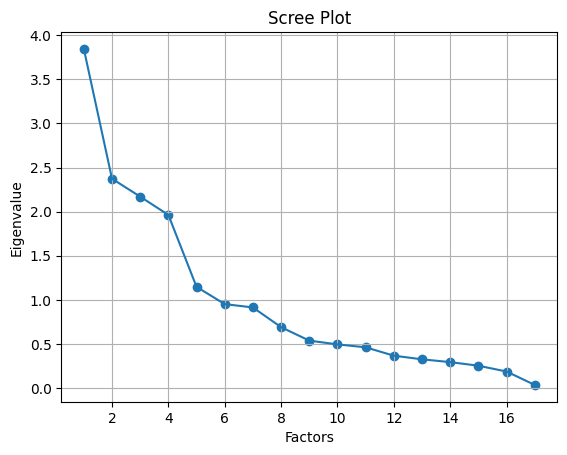

In [26]:
# Create scree plot using matplotlib
plt.scatter(range(1,df.shape[1]+1),ev)
plt.plot(range(1,df.shape[1]+1),ev)
plt.title('Scree Plot')
plt.xlabel('Factors')
plt.ylabel('Eigenvalue')
plt.grid()
plt.show()

The scree plot method draws a straight line for each factor and its eigenvalues. Number eigenvalues greater than one considered as the number of factors. Here only for 5-factors eigenvalues are greater than one. It means we need to choose only 5 factors (or unobserved variables).

### **Parallel Analysis:**

This method compares the observed eigenvalues with those obtained from random data.  </br> 
Factors with eigenvalues larger than those of the random data are retained.

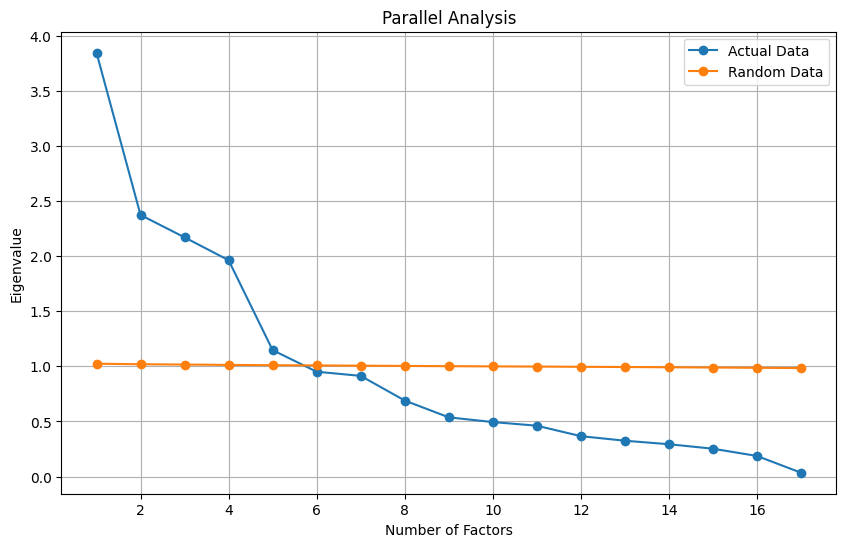

Number of factors to retain: 5


In [27]:
import numpy as np
from factor_analyzer.factor_analyzer import calculate_bartlett_sphericity

def parallel_analysis(df, n_iter=100, percentile=95):
    np.random.seed(42)
    _, n_variables = df.shape

    # Perform factor analysis on original data
    fa = FactorAnalyzer()
    fa.fit(df)
    actual_eigenvalues, _ = fa.get_eigenvalues()

    # Generate random datasets and compute eigenvalues
    random_eigenvalues = []
    for _ in range(n_iter):
        random_data = np.random.normal(size=df.shape)
        fa.fit(random_data)
        random_eigenvalues.append(fa.get_eigenvalues()[0])

    # Calculate mean eigenvalues of random datasets
    random_eigenvalues = np.array(random_eigenvalues)
    mean_random_eigenvalues = np.percentile(random_eigenvalues, percentile, axis=0)

    # Plot the actual eigenvalues vs random eigenvalues
    plt.figure(figsize=(10, 6))
    plt.plot(range(1, n_variables + 1), actual_eigenvalues, marker='o', label='Actual Data')
    plt.plot(range(1, n_variables + 1), mean_random_eigenvalues, marker='o', label='Random Data')
    plt.xlabel('Number of Factors')
    plt.ylabel('Eigenvalue')
    plt.title('Parallel Analysis')
    plt.legend()
    plt.grid()
    plt.show()

    # Count factors where actual eigenvalue > mean random eigenvalue
    retained_factors = sum(actual_eigenvalues > mean_random_eigenvalues)
    print(f"Number of factors to retain: {retained_factors}")

# Perform Parallel Analysis
parallel_analysis(df)


**We choose only 5 factors**

## Principal Axis Factoring (PAF)

In [28]:
# Then, we repeat the factor analyzer using five factors, fitting it, and print the factor loadings for each variables.
fa = FactorAnalyzer(5, rotation='Promax')
fa.fit(df)


FactorAnalyzer(n_factors=5, rotation_kwargs={})

In [29]:
# Get communalities
print("\nCommunalities (PAF):")

# Get communalities
# Create a DataFrame for communalities
communalities_df = pd.DataFrame(fa.get_communalities(), columns=['Communality'], index=df.columns)

# Function to highlight high communalities
def highlight_high_communalities(val):
    if val > 0.6:  # You can change this threshold based on your preference
        return 'background-color: lightgreen'
    else:
        return ''

# Apply the highlighting function
styled_communalities = communalities_df.style.applymap(highlight_high_communalities)

# Display the styled DataFrame
styled_communalities


Communalities (PAF):


,Communality
Flight Distance,0.051613
Inflight wifi service,0.527169
Departure/Arrival time convenient,0.367679
Ease of Online booking,0.775216
Gate location,0.480127
Food and drink,0.690471
Online boarding,0.865746
Seat comfort,0.561862
Inflight entertainment,0.723227
On-board service,0.508774


**Communalities represent** the proportion of a variable's variance that is explained by the extracted factors. In other words, they show how much of each variable's variance can be accounted for by the factors in the model.</br>

How to Interpret Communalities </br>
**Range:** Communalities range from 0 to 1:</br>

**0:** None of the variance is explained by the factors.</br>
**1:** All the variance is explained by the factors.</br>

**High Communality:** A value close to 1 indicates that the variable is well represented by the factors.</br>

**Low Communality:** A value close to 0 indicates that the variable is poorly represented by the factors.

The above output is not human-eye friendly, so we make the below dataframes.

In [30]:
print("Factor loadings (PAF)")
# Example factor loading matrix
lmatrix = pd.DataFrame(
    fa.loadings_, 
    index=list(df.columns), 
    columns=['Factor 1', 'Factor 2', 'Factor 3', 'Factor 4', 'Factor 5']
)

# Function to apply color based on loading values
def highlight_high_loadings(val):
    if abs(val) > 0.5:
        return 'background-color: lightblue'
    else:
        return ''

# Apply the highlighting function
styled_lmatrix = lmatrix.style.applymap(highlight_high_loadings)

# Display the styled DataFrame
styled_lmatrix


Factor loadings (PAF)


,Factor 1,Factor 2,Factor 3,Factor 4,Factor 5
Flight Distance,0.020687,0.051505,0.006952,-0.042569,0.216037
Inflight wifi service,-0.004060,0.020926,-0.009006,0.642647,0.337103
Departure/Arrival time convenient,0.017829,0.072896,0.001611,0.590550,-0.115307
Ease of Online booking,-0.121466,-0.063524,-0.003932,0.803517,0.332824
Gate location,0.077634,-0.010231,0.007149,0.656189,-0.208232
Food and drink,0.820239,-0.117753,-0.008780,0.035666,-0.049634
Online boarding,0.017648,-0.143972,-0.010870,0.102077,0.913329
Seat comfort,0.719368,-0.088672,-0.005370,-0.032213,0.188260
Inflight entertainment,0.758409,0.373325,0.005942,0.032534,-0.087047
On-board service,-0.017558,0.712907,-0.012037,-0.007270,0.005577


* Factor 1: Cleanliness, Food and Drink, Inflight Entertainment, Seat Comfort
* Factor 2: Baggage Handling, Onboard Services, Inflight service
* Factor 3: Arrival and Departure Delay,Departure Delay in Minutes
* Factor 4: Departure/Arrival time convenient, Ease of Online booking, Gate location,Inflight wifi service
* Factor 5: Online Boarding

Of course we can simulate the number of factors towards other numbers, but I will stop until this point and you can further explore other possibilities.

In [31]:
# Get variance of each factors
fa.get_factor_variance()

(array([2.54702077, 2.37779565, 1.93372134, 1.85758261, 1.25976037]),
 array([0.14982475, 0.13987033, 0.11374831, 0.10926957, 0.07410355]),
 array([0.14982475, 0.28969508, 0.4034434 , 0.51271296, 0.58681651]))

 ## Maximum Likelihood Estimation (MLE)

In [32]:
#Factor analyzer using five factors
fa_mle = FactorAnalyzer(method='ml', n_factors=5, rotation= 'Oblimin')
fa_mle.fit(df)


FactorAnalyzer(method='ml', n_factors=5, rotation='oblimin', rotation_kwargs={})

In [33]:
# Get factor loadings
print("\nFactor loadings (MLE):")
# Example factor loading matrix
lmatrix_mle = pd.DataFrame(
    fa_mle.loadings_, 
    index=list(df.columns), 
    columns=['Factor 1', 'Factor 2', 'Factor 3', 'Factor 4', 'Factor 5']
)

# Function to apply color based on loading values
def highlight_high_loadings(val):
    if abs(val) > 0.5:
        return 'background-color: lightblue'
    else:
        return ''

# Apply the highlighting function
styled_lmatrix = lmatrix_mle.style.applymap(highlight_high_loadings)

# Display the styled DataFrame
styled_lmatrix


Factor loadings (MLE):


,Factor 1,Factor 2,Factor 3,Factor 4,Factor 5
Flight Distance,0.035404,0.080032,-0.046888,0.006712,0.220922
Inflight wifi service,0.057359,0.068151,0.709428,-0.004838,0.165456
Departure/Arrival time convenient,0.002594,0.032745,0.555554,0.001309,-0.152452
Ease of Online booking,-0.057018,-0.022088,0.877307,-0.000936,0.100651
Gate location,0.061674,-0.056091,0.623130,0.004437,-0.262648
Food and drink,0.818355,-0.127258,0.040703,-0.013504,-0.059093
Online boarding,0.045941,0.014156,0.074337,-0.001155,0.907917
Seat comfort,0.715830,-0.064249,-0.066050,-0.008068,0.208005
Inflight entertainment,0.777343,0.346417,0.031331,0.004806,-0.047198
On-board service,0.022426,0.694923,-0.025758,-0.006501,0.075118


* Factor 1: Cleanliness, Food and Drink, Inflight Entertainment, Seat Comfort,
* Factor 2: On-board service, Baggage handling,Inflight service
* Factor 3:Inflight wifi service,Departure/Arrival time convenient,Ease of Online booking, Gate location 
* Factor 4: Arrival and Departure Delay, Departure Delay in Minute 
* Factor 5: Online boarding

In [34]:
# Get communalities
print("\nCommunalities (MLE):")
# Create a DataFrame for communalities
communalities_df = pd.DataFrame(fa_mle.get_communalities(), columns=['Communality'], index=df.columns)

# Function to highlight high communalities
def highlight_high_communalities(val):
    if val > 0.6:  # You can change this threshold based on your preference
        return 'background-color: lightgreen'
    else:
        return ''

# Apply the highlighting function
styled_communalities = communalities_df.style.applymap(highlight_high_communalities)

# Display the styled DataFrame
styled_communalities


Communalities (MLE):


,Communality
Flight Distance,0.058709
Inflight wifi service,0.538622
Departure/Arrival time convenient,0.332963
Ease of Online booking,0.783539
Gate location,0.464245
Food and drink,0.691230
Online boarding,0.832151
Seat comfort,0.564235
Inflight entertainment,0.727499
On-board service,0.489770


In [35]:
# Get variance of each factors
fa_mle.get_factor_variance()

(array([2.53038012, 2.17807045, 1.99728973, 1.93418901, 1.10688558]),
 array([0.14884589, 0.12812179, 0.11748763, 0.11377582, 0.06511092]),
 array([0.14884589, 0.27696768, 0.39445531, 0.50823114, 0.57334205]))